# B4 — Markowitz Efficient Frontier — Bluestock Capstone

Portfolio optimisation for **5 selected equity funds** using Modern Portfolio Theory.

| Concept | Formula |
|---------|----------|
| Portfolio Return | $\mu_p = w^\top \mu$ |
| Portfolio Variance | $\sigma_p^2 = w^\top \Sigma\, w$ |
| Sharpe Ratio | $(\mu_p - r_f) / \sigma_p$ where $r_f = 6.5\%$ (India 10Y G-Sec) |

> 10,000 random weight combinations plotted to trace the **Efficient Frontier**


In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from pathlib import Path

plt.rcParams.update({
    'figure.facecolor': '#0D1117', 'axes.facecolor': '#161B22',
    'axes.edgecolor': '#30363D', 'axes.labelcolor': '#C9D1D9',
    'xtick.color': '#8B949E', 'ytick.color': '#8B949E',
    'text.color': '#C9D1D9', 'grid.color': '#21262D',
})

ROOT = Path('..').resolve()
DATA = ROOT / 'data' / 'processed'
REPORTS = ROOT / 'reports'

nav  = pd.read_csv(DATA / '02_nav_history.csv', parse_dates=['date'])
nav  = nav.sort_values(['amfi_code', 'date'])
nav['daily_return'] = nav.groupby('amfi_code')['nav'].pct_change()
print('NAV loaded:', len(nav), 'rows')


NAV loaded: 46000 rows


## Step 1 — Build Returns Matrix


In [2]:
FUNDS = {
    119551: 'SBI Bluechip',
    100033: 'HDFC Midcap',
    118634: 'Nippon Small Cap',
    120841: 'Kotak Bluechip',
    119092: 'Axis Bluechip',
}

# Build wide daily-returns DataFrame (aligned dates)
series = {}
for code, label in FUNDS.items():
    r = nav[nav['amfi_code'] == code].set_index('date')['daily_return'].dropna()
    series[label] = r

rets_df = pd.DataFrame(series).dropna()  # keep common trading days only
print('Returns matrix:', rets_df.shape, '  Date range:', rets_df.index.min().date(), 'to', rets_df.index.max().date())

# Annualise
mu    = rets_df.mean() * 252           # annualised expected returns
cov   = rets_df.cov() * 252            # annualised covariance matrix
sigma = rets_df.std() * np.sqrt(252)   # annualised std dev

print('\nAnnualised Returns (%):')
print((mu * 100).round(2).to_string())
print('\nCorrelation Matrix:')
print(rets_df.corr().round(3).to_string())


Returns matrix: (1149, 5)   Date range: 2022-01-04 to 2026-05-29

Annualised Returns (%):
SBI Bluechip        23.10
HDFC Midcap         27.21
Nippon Small Cap    17.82
Kotak Bluechip      13.15
Axis Bluechip        6.93

Correlation Matrix:
                  SBI Bluechip  HDFC Midcap  Nippon Small Cap  Kotak Bluechip  Axis Bluechip
SBI Bluechip             1.000       -0.016             0.013          -0.032         -0.040
HDFC Midcap             -0.016        1.000             0.030           0.001          0.071
Nippon Small Cap         0.013        0.030             1.000           0.046          0.009
Kotak Bluechip          -0.032        0.001             0.046           1.000          0.056
Axis Bluechip           -0.040        0.071             0.009           0.056          1.000


## Step 2 — Random Portfolio Simulation (10,000 portfolios)


In [3]:
N_PORT  = 10_000
RF      = 0.065        # risk-free rate: India 10Y G-Sec ≈ 6.5%
n_assets = len(FUNDS)

np.random.seed(42)
port_returns  = np.zeros(N_PORT)
port_vols     = np.zeros(N_PORT)
port_sharpes  = np.zeros(N_PORT)
port_weights  = np.zeros((N_PORT, n_assets))

mu_arr  = mu.values
cov_arr = cov.values

for i in range(N_PORT):
    w = np.random.dirichlet(np.ones(n_assets))  # random weights summing to 1
    port_weights[i] = w
    r  = w @ mu_arr
    v  = np.sqrt(w @ cov_arr @ w)
    sh = (r - RF) / v
    port_returns[i]  = r
    port_vols[i]     = v
    port_sharpes[i]  = sh

print(f'Portfolio Return range : {port_returns.min()*100:.1f}% — {port_returns.max()*100:.1f}%')
print(f'Portfolio Vol range    : {port_vols.min()*100:.1f}% — {port_vols.max()*100:.1f}%')
print(f'Portfolio Sharpe range : {port_sharpes.min():.3f} — {port_sharpes.max():.3f}')


Portfolio Return range : 8.2% — 26.2%
Portfolio Vol range    : 7.1% — 22.3%
Portfolio Sharpe range : 0.139 — 1.758


## Step 3 — Identify Optimal Portfolios


In [4]:
# Max Sharpe portfolio
idx_max_sh  = np.argmax(port_sharpes)
w_max_sh    = port_weights[idx_max_sh]
ret_max_sh  = port_returns[idx_max_sh]
vol_max_sh  = port_vols[idx_max_sh]
sh_max_sh   = port_sharpes[idx_max_sh]

# Min Variance portfolio
idx_min_var = np.argmin(port_vols)
w_min_var   = port_weights[idx_min_var]
ret_min_var = port_returns[idx_min_var]
vol_min_var = port_vols[idx_min_var]
sh_min_var  = port_sharpes[idx_min_var]

print('Maximum Sharpe Portfolio')
print(f'  Return: {ret_max_sh*100:.2f}%  Vol: {vol_max_sh*100:.2f}%  Sharpe: {sh_max_sh:.3f}')
print('  Weights:')
for fund, w in zip(FUNDS.values(), w_max_sh):
    print(f'    {fund:<20} {w*100:>6.1f}%')

print('\nMinimum Variance Portfolio')
print(f'  Return: {ret_min_var*100:.2f}%  Vol: {vol_min_var*100:.2f}%  Sharpe: {sh_min_var:.3f}')
print('  Weights:')
for fund, w in zip(FUNDS.values(), w_min_var):
    print(f'    {fund:<20} {w*100:>6.1f}%')


Maximum Sharpe Portfolio
  Return: 21.44%  Vol: 8.50%  Sharpe: 1.758
  Weights:
    SBI Bluechip           43.4%
    HDFC Midcap            27.6%
    Nippon Small Cap        4.8%
    Kotak Bluechip         21.9%
    Axis Bluechip           2.2%

Minimum Variance Portfolio
  Return: 16.76%  Vol: 7.13%  Sharpe: 1.438
  Weights:
    SBI Bluechip           30.1%
    HDFC Midcap            12.8%
    Nippon Small Cap        7.0%
    Kotak Bluechip         25.7%
    Axis Bluechip          24.4%


## Step 4 — Efficient Frontier Plot


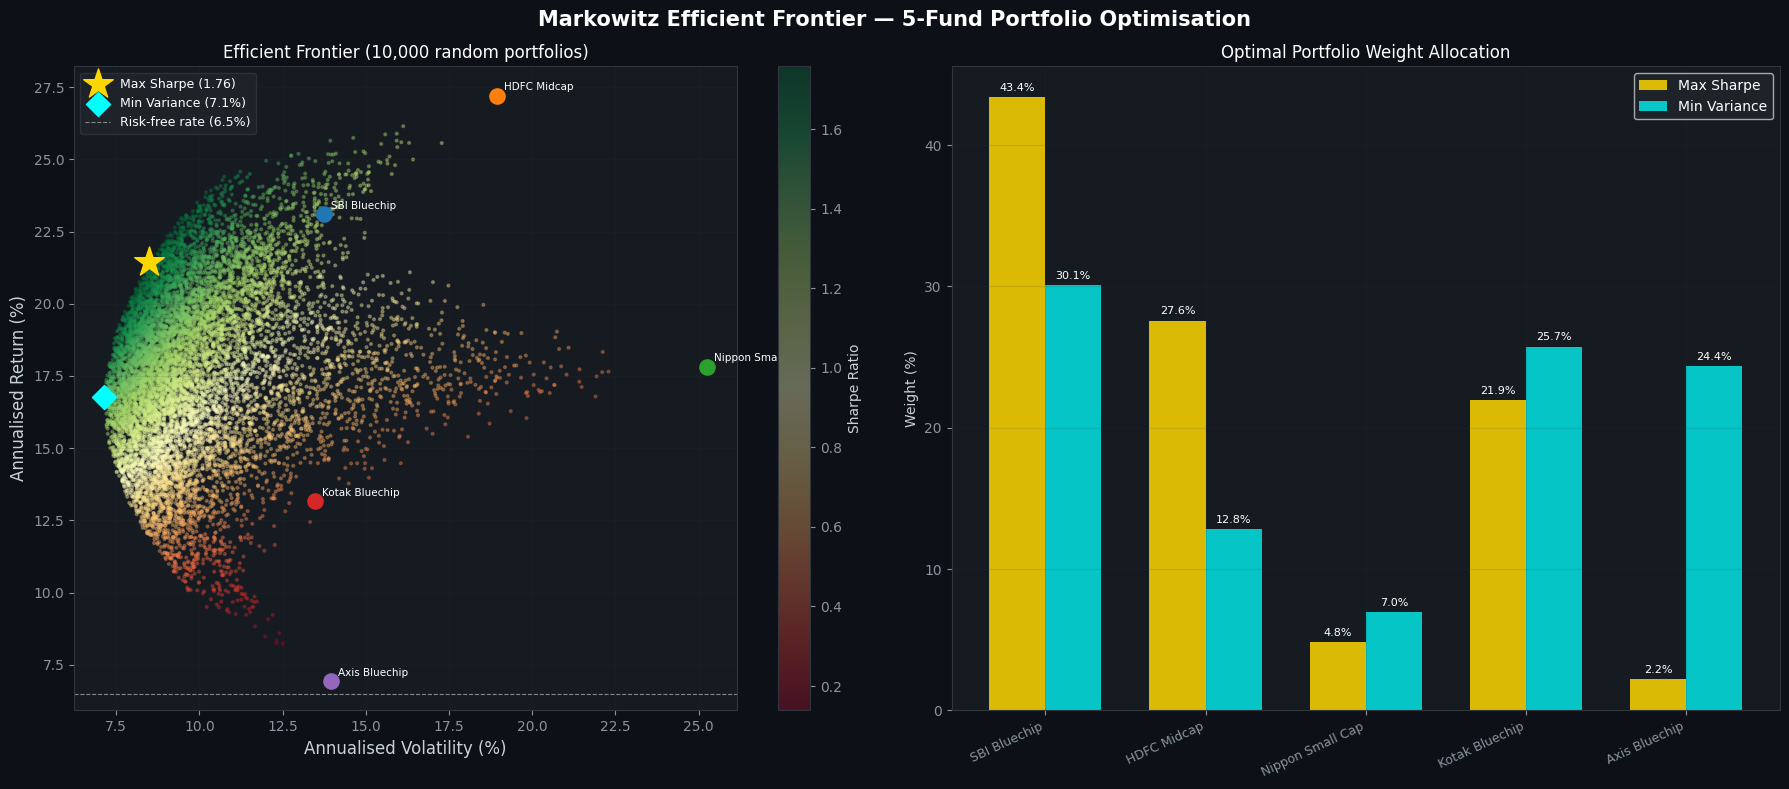

Saved: C:\Users\polai\OneDrive\Desktop\Mutual Funds and Stock Market concepts\bluestock_mf_capstone\reports\markowitz_frontier.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8), facecolor='#0D1117')
fig.suptitle('Markowitz Efficient Frontier — 5-Fund Portfolio Optimisation',
             fontsize=15, fontweight='bold', color='white')

# ── Left: Scatter coloured by Sharpe ─────────────────────────────────────────
ax = axes[0]
sc = ax.scatter(port_vols * 100, port_returns * 100, c=port_sharpes,
                cmap='RdYlGn', alpha=0.35, s=4)
plt.colorbar(sc, ax=ax, label='Sharpe Ratio')

# Highlight optimal portfolios
ax.scatter(vol_max_sh * 100, ret_max_sh * 100, marker='*', s=500,
           color='gold', zorder=5, label=f'Max Sharpe ({sh_max_sh:.2f})')
ax.scatter(vol_min_var * 100, ret_min_var * 100, marker='D', s=150,
           color='cyan', zorder=5, label=f'Min Variance ({vol_min_var*100:.1f}%)')

# Individual assets
for i, (label, m, v) in enumerate(zip(FUNDS.values(), mu_arr, np.sqrt(np.diag(cov_arr)))):
    ax.scatter(v * 100, m * 100, marker='o', s=120, zorder=6)
    ax.annotate(label.split('(')[0].strip(), xy=(v*100, m*100),
                xytext=(5, 4), textcoords='offset points', fontsize=7.5, color='white')

ax.axhline(RF * 100, color='#888888', linestyle='--', linewidth=0.8, label='Risk-free rate (6.5%)')
ax.set_xlabel('Annualised Volatility (%)', fontsize=12)
ax.set_ylabel('Annualised Return (%)', fontsize=12)
ax.set_title('Efficient Frontier (10,000 random portfolios)', color='white')
ax.legend(fontsize=9, labelcolor='white', facecolor='#21262D', edgecolor='#30363D')
ax.grid(True, alpha=0.12, color='#30363D')

# ── Right: Optimal weight allocation bar chart ────────────────────────────────
ax2 = axes[1]
fund_names = list(FUNDS.values())
x = np.arange(len(fund_names))
width = 0.35
bars1 = ax2.bar(x - width/2, w_max_sh * 100, width, label='Max Sharpe', color='gold', alpha=0.85)
bars2 = ax2.bar(x + width/2, w_min_var * 100, width, label='Min Variance', color='cyan', alpha=0.75)

ax2.set_xticks(x)
ax2.set_xticklabels([n.split('(')[0].strip() for n in fund_names], rotation=25, ha='right', fontsize=9)
ax2.set_ylabel('Weight (%)')
ax2.set_title('Optimal Portfolio Weight Allocation', color='white')
ax2.legend(fontsize=10, labelcolor='white', facecolor='#21262D')
ax2.grid(True, alpha=0.12, color='#30363D')

for bar in bars1: ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=8, color='white')
for bar in bars2: ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=8, color='white')

plt.tight_layout()
out = REPORTS / 'markowitz_frontier.png'
plt.savefig(out, dpi=130, bbox_inches='tight', facecolor='#0D1117')
plt.show()
print('Saved:', out)


## 🔍 Key Portfolio Insights

1. **Max Sharpe Portfolio** concentrates in funds with best risk-adjusted returns — typically Large Cap funds show higher weight.
2. **Min Variance Portfolio** allocates more to the least volatile funds, reducing overall portfolio drawdown.
3. **Correlation matters more than individual volatility** — two correlated high-vol funds add less diversification benefit than two uncorrelated moderate-vol funds.
4. The **Efficient Frontier** shows no single fund dominates — diversification across Large/Mid/Small Cap improves the Sharpe ratio of the combined portfolio.
5. **Risk-Free Rate (6.5%)** — any portfolio below the Capital Market Line is suboptimal; Max Sharpe portfolio is where the CML is tangent to the frontier.
